In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import dataset_manager as dm

In [4]:
df = pd.concat([pd.read_csv("train.csv")])

Посмотрим на Age разбросы

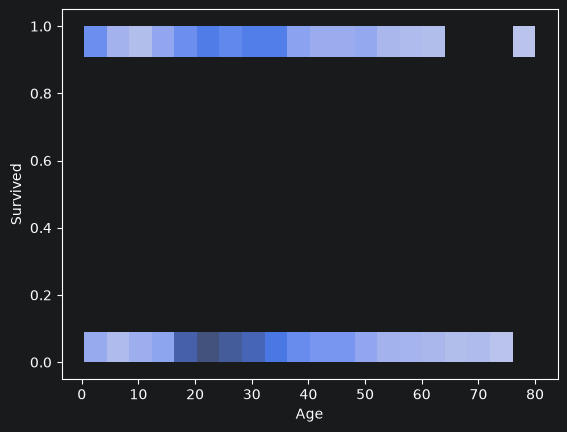

In [5]:
sns.histplot(data=df, x="Age", y="Survived",
             stat="density", common_norm=False, element="step")
plt.show()

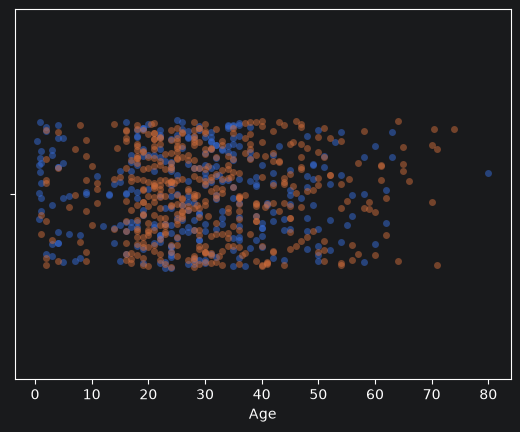

In [8]:
sns.stripplot(x=df[df["Survived"] == 1]["Age"], jitter=0.2, alpha=0.5)
sns.stripplot(x=df[df["Survived"] == 0]["Age"], jitter=0.2, alpha=0.5)
plt.show()

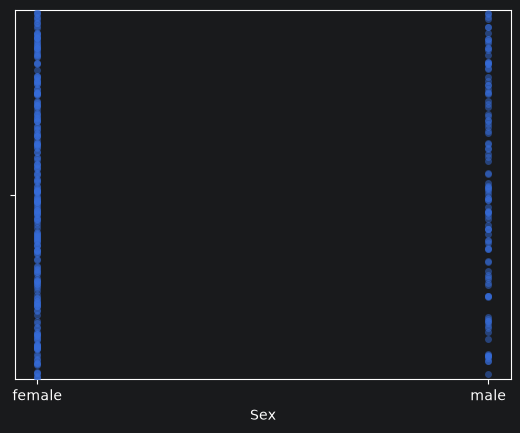

In [12]:
sns.stripplot(x=df[df["Survived"] == 1]["Sex"], jitter=0.5, alpha=0.5)
plt.show()

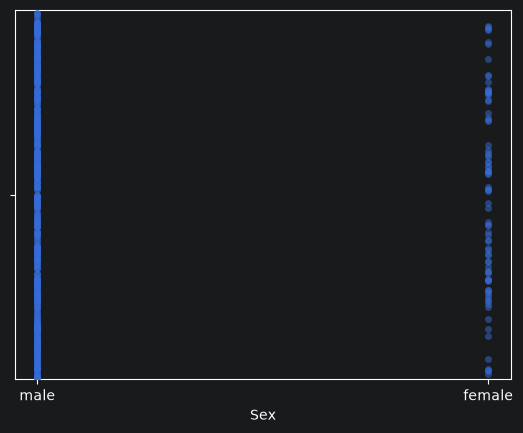

In [13]:
sns.stripplot(x=df[df["Survived"] == 0]["Sex"], jitter=0.5, alpha=0.5)
plt.show()

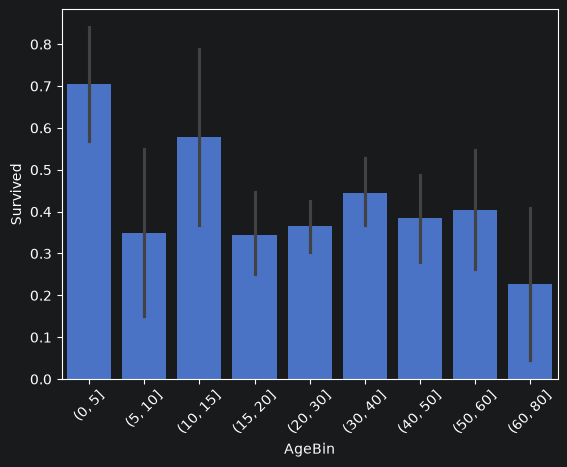

              mean  count
AgeBin                   
(0, 5]    0.704545     44
(5, 10]   0.350000     20
(10, 15]  0.578947     19
(15, 20]  0.343750     96
(20, 30]  0.365217    230
(30, 40]  0.445161    155
(40, 50]  0.383721     86
(50, 60]  0.404762     42
(60, 80]  0.227273     22


In [16]:
df["AgeBin"] = pd.cut(df["Age"], bins=[0, 5, 10, 15, 20, 30, 40, 50, 60, 80])

sns.barplot(data=df, x="AgeBin", y="Survived")
plt.xticks(rotation=45)
plt.show()

print(df.groupby("AgeBin", observed=True)["Survived"].agg(["mean", "count"]))

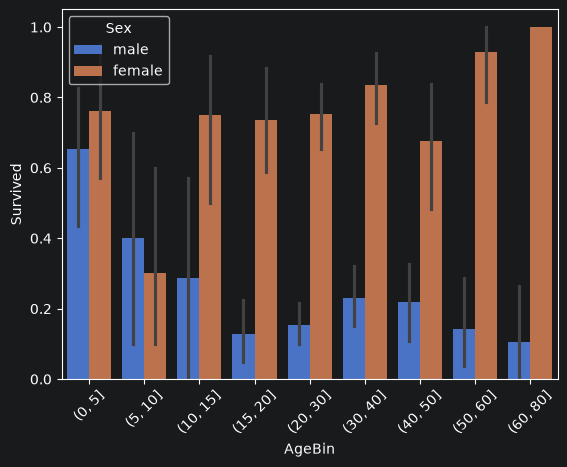

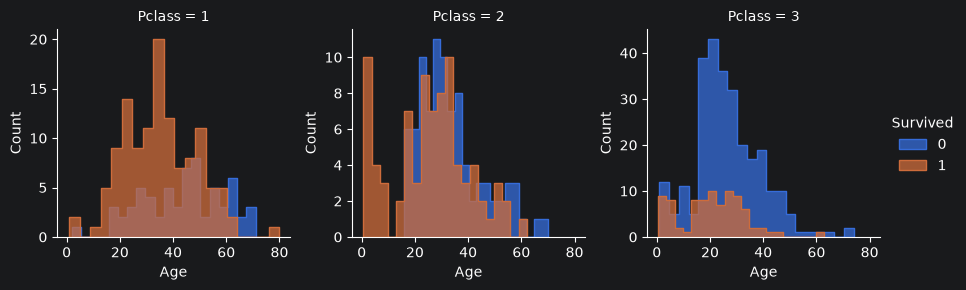

In [17]:
sns.barplot(data=df, x="AgeBin", y="Survived", hue="Sex")
plt.xticks(rotation=45)
plt.show()

g = sns.FacetGrid(df, col="Pclass", hue="Survived", sharey=False)
g.map(sns.histplot, "Age", bins=20, element="step")
g.add_legend()
plt.show()